# Topology Variability Analysis

Does higher grid-topology variability correlate with a larger advantage of graph-based
GNN methods over the no-edges baseline?

Three settings are compared:
1. **14-bus** — baseline, no opponent
2. **14-bus + opponent** — forced line disconnections
3. **36-bus (IL)** — larger grid, imitation-learning pipeline

In [1]:
import os
import json
from pathlib import Path
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

if Path.cwd().name == "experiments":
    os.chdir("..")
ROOT = Path.cwd()

FIGURES = ROOT / "experiments" / "figures" / "topology_variability"
FIGURES.mkdir(exist_ok=True, parents=True)

sns.set_style("whitegrid")
plt.rcParams.update({"font.size": 11})

METHOD_COLORS = {"no_edges": "tab:orange", "substation": "tab:blue"}
SETTING_COLORS = {"14-bus": "tab:green", "14-bus + opponent": "tab:red", "36-bus (IL)": "tab:purple"}

print(f"ROOT: {ROOT}")
print(f"Figures -> {FIGURES}")

ROOT: /home/adrian/Dev/NRI-for-explainable-RL-in-Power-Grids
Figures -> /home/adrian/Dev/NRI-for-explainable-RL-in-Power-Grids/experiments/figures/topology_variability


In [2]:
# Cluster results mount — works locally over SSHFS or when data is synced.
CLUSTER_MOUNT = Path("/home/adrian/.mnt/unicluster")
if CLUSTER_MOUNT.exists():
    R  = CLUSTER_MOUNT / "results"
    JR = CLUSTER_MOUNT / "results" / "junior"
else:
    R  = ROOT / "results"
    JR = ROOT / "results" / "junior"

# Settings with PPO post-training analysis (topology_variability + survival/summary.json).
# Values are base dirs; trial dirs are found by globbing CustomPPO*/ inside them.
SETTINGS = {
    "14-bus": {
        "no_edges":   R / "2026_10_28_compare_graph_obs_spaces_IEEE14/no_edges",
        "substation": R / "2026_10_28_compare_graph_obs_spaces_IEEE14/substation",
    },
    "14-bus + opponent": {
        "no_edges":   R / "2026_11_05_topology_variability_study/14bus_opponent/no_edges",
        "substation": R / "2026_11_05_topology_variability_study/14bus_opponent/substation",
    },
}

# 36-bus Junior: survival from imitation_rollout.py CSVs; no variability data.
JUNIOR_DIRS = {
    "no_edges":   JR / "2026_11_05_topology_variability_study/36bus_junior/no_edges/rollout",
    "substation": JR / "2026_11_05_topology_variability_study/36bus_junior/substation/rollout",
}

# Data availability summary
print(f"Results root: {R}")
for setting, methods in SETTINGS.items():
    for method, base_dir in methods.items():
        n = len(sorted(base_dir.glob("CustomPPO*/"))) if base_dir.exists() else 0
        print(f"  {setting} / {method}: {n} trials")
for method, d in JUNIOR_DIRS.items():
    n = len(list(d.glob("episodes_*.csv"))) if d.exists() else 0
    print(f"  36-bus (IL) / {method}: {n} CSV shards")

Results root: /home/adrian/.mnt/unicluster/results
  14-bus / no_edges: 5 trials
  14-bus / substation: 5 trials


  14-bus + opponent / no_edges: 3 trials
  14-bus + opponent / substation: 2 trials
  36-bus (IL) / no_edges: 16 CSV shards


  36-bus (IL) / substation: 16 CSV shards


In [3]:
def load_variability(trial_dir: Path) -> Optional[dict]:
    """Load topology_variability.json from a PPO trial's analysis output."""
    path = trial_dir / "analysis" / "topology_variability" / "topology_variability.json"
    if not path.exists():
        return None
    with open(path) as f:
        return json.load(f)


def load_survival_summary(trial_dir: Path) -> Optional[dict]:
    """Load survival/summary.json from a PPO trial's analysis output."""
    path = trial_dir / "analysis" / "survival" / "summary.json"
    if not path.exists():
        return None
    with open(path) as f:
        return json.load(f)


def load_element_variability(trial_dir: Path) -> Optional[np.ndarray]:
    """Load per-element variability array from a PPO trial's analysis output."""
    path = trial_dir / "analysis" / "topology_variability" / "element_variability.npy"
    if not path.exists():
        return None
    return np.load(path)


def load_junior_survival(rollout_dir: Path, method: str) -> list[dict]:
    """Survival statistics from imitation_rollout.py episode CSVs (val + test combined).

    Returns one record per method (all seeds/shards pooled), matching the
    format used by load_survival_summary so both can live in df_surv.
    """
    if not rollout_dir.exists():
        return []
    dfs = []
    for csv_path in sorted(rollout_dir.glob("episodes_*.csv")):
        try:
            dfs.append(pd.read_csv(csv_path))
        except Exception:
            pass
    if not dfs:
        return []
    df = pd.concat(dfs, ignore_index=True)
    return [{
        "setting": "36-bus (IL)",
        "method": method,
        "seed": 0,
        "completed_episodes_pct": float(df["survived"].mean() * 100),
        "survived_steps_pct": float((df["steps_survived"] / df["max_step"]).mean() * 100),
        "survived_steps_mean": float(df["steps_survived"].mean()),
    }]

In [4]:
var_records = []
surv_records = []
available_settings = []

# --- PPO settings (have variability + survival from post-training analysis) ---
for setting, methods in SETTINGS.items():
    setting_has_data = False
    for method, base_dir in methods.items():
        dirs = sorted(base_dir.glob("CustomPPO*/")) if base_dir.exists() else []
        for seed_idx, d in enumerate(dirs):
            var  = load_variability(d)
            surv = load_survival_summary(d)

            if var is not None:
                var_records.append({
                    "setting": setting,
                    "method": method,
                    "seed": seed_idx,
                    "mean_element_variability": var["mean_element_variability"],
                    "topology_entropy_normalised": var["topology_entropy_normalised"],
                    "n_unique_topologies": var["n_unique_topologies"],
                    "total_steps": var["total_steps"],
                })
                setting_has_data = True

            if surv is not None:
                surv_records.append({
                    "setting": setting,
                    "method": method,
                    "seed": seed_idx,
                    "completed_episodes_pct": surv["completed_episodes_pct"],
                    "survived_steps_pct": surv["survived_steps_pct"],
                    "survived_steps_mean": surv["survived_steps_mean"],
                })
                setting_has_data = True

    if setting_has_data:
        available_settings.append(setting)

# --- 36-bus Junior (survival only, from rollout CSVs) ---
junior_records = []
for method, rollout_dir in JUNIOR_DIRS.items():
    junior_records.extend(load_junior_survival(rollout_dir, method))

if junior_records:
    surv_records.extend(junior_records)
    if "36-bus (IL)" not in available_settings:
        available_settings.append("36-bus (IL)")

df_var  = pd.DataFrame(var_records)
df_surv = pd.DataFrame(surv_records)

print(f"Settings with data: {available_settings}")
if not df_var.empty:
    print(f"\nVariability records: {len(df_var)}")
    print(df_var.groupby(["setting", "method"]).size().to_string())
if not df_surv.empty:
    print(f"\nSurvival records: {len(df_surv)}")
    print(df_surv.groupby(["setting", "method"])[["survived_steps_pct"]].mean().round(1).to_string())

if df_var.empty:
    print("\nNo variability data found. Run rerun_analysis.py on existing checkpoints first.")

Settings with data: ['14-bus', '14-bus + opponent', '36-bus (IL)']

Variability records: 5
setting            method    
14-bus + opponent  no_edges      3
                   substation    2

Survival records: 17
                              survived_steps_pct
setting           method                        
14-bus            no_edges                  99.1
                  substation                99.2
14-bus + opponent no_edges                   7.3
                  substation                 8.2
36-bus (IL)       no_edges                  34.8
                  substation                38.4


## Tables

In [5]:
if not df_var.empty:
    var_agg = (
        df_var.groupby(["setting", "method"])
        .agg(
            elem_var_mean=("mean_element_variability", "mean"),
            elem_var_std=("mean_element_variability", "std"),
            entropy_mean=("topology_entropy_normalised", "mean"),
            entropy_std=("topology_entropy_normalised", "std"),
            n_unique_mean=("n_unique_topologies", "mean"),
            n_unique_std=("n_unique_topologies", "std"),
        )
        .round(4)
    )

    # Format as mean +/- std strings
    display_df = pd.DataFrame({
        "Element Variability": var_agg.apply(
            lambda r: f"{r['elem_var_mean']:.4f} +/- {r['elem_var_std']:.4f}", axis=1
        ),
        "Normalised Entropy": var_agg.apply(
            lambda r: f"{r['entropy_mean']:.3f} +/- {r['entropy_std']:.3f}", axis=1
        ),
        "Unique Topologies": var_agg.apply(
            lambda r: f"{r['n_unique_mean']:.0f} +/- {r['n_unique_std']:.0f}", axis=1
        ),
    })

    print("Topology Variability by Setting x Method (mean +/- std across seeds)\n")
    display(display_df)
else:
    print("No variability data available.")

Topology Variability by Setting x Method (mean +/- std across seeds)



Element Variability Normalised Entropy  \
setting           method                                              
14-bus + opponent no_edges     0.1206 +/- 0.0125    0.628 +/- 0.037   
                  substation   0.1329 +/- 0.0011    0.654 +/- 0.025   

                             Unique Topologies  
setting           method                        
14-bus + opponent no_edges           55 +/- 10  
                  substation          49 +/- 1

In [6]:
if not df_surv.empty:
    surv_agg = (
        df_surv.groupby(["setting", "method"])
        .agg(
            ep_pct_mean=("completed_episodes_pct", "mean"),
            ep_pct_std=("completed_episodes_pct", "std"),
            step_pct_mean=("survived_steps_pct", "mean"),
            step_pct_std=("survived_steps_pct", "std"),
        )
        .round(2)
    )

    display_df = pd.DataFrame({
        "Completed Episodes %": surv_agg.apply(
            lambda r: f"{r['ep_pct_mean']:.1f} +/- {r['ep_pct_std']:.1f}", axis=1
        ),
        "Survived Steps %": surv_agg.apply(
            lambda r: f"{r['step_pct_mean']:.1f} +/- {r['step_pct_std']:.1f}", axis=1
        ),
    })

    print("Survival by Setting x Method (mean +/- std across seeds)\n")
    display(display_df)
else:
    print("No survival data available.")

Survival by Setting x Method (mean +/- std across seeds)



Completed Episodes % Survived Steps %
setting           method                                          
14-bus            no_edges           98.4 +/- 1.7     99.1 +/- 0.9
                  substation         98.8 +/- 1.8     99.2 +/- 1.0
14-bus + opponent no_edges            0.0 +/- 0.0      7.3 +/- 1.1
                  substation          0.0 +/- 0.0      8.2 +/- 1.7
36-bus (IL)       no_edges           14.9 +/- nan     34.8 +/- nan
                  substation         20.5 +/- nan     38.4 +/- nan

## Plots

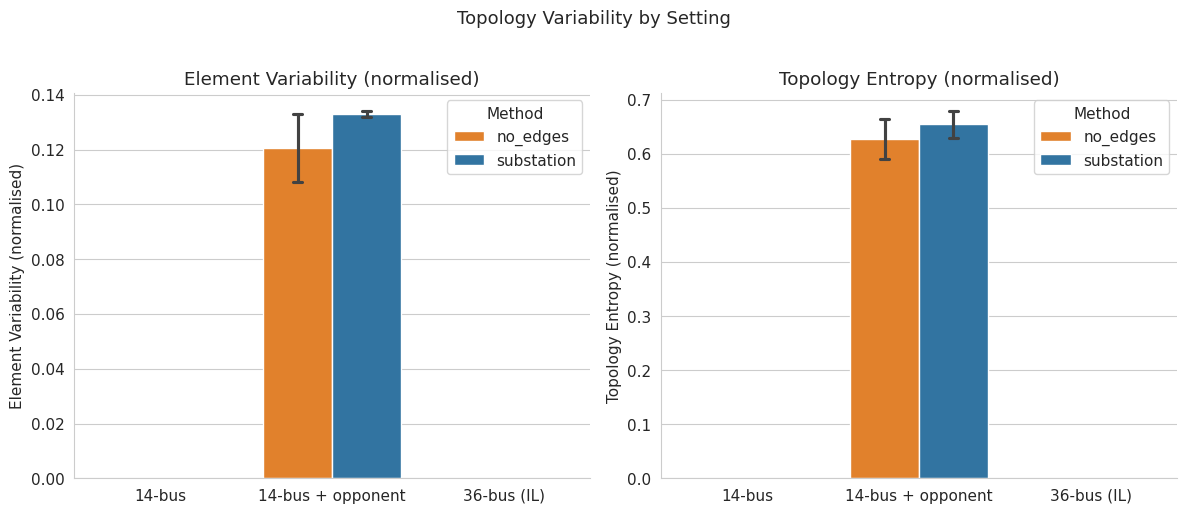

In [7]:
if not df_var.empty and available_settings:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    for ax, metric, label in [
        (axes[0], "mean_element_variability", "Element Variability (normalised)"),
        (axes[1], "topology_entropy_normalised", "Topology Entropy (normalised)"),
    ]:
        sub = df_var[df_var["setting"].isin(available_settings)]
        sns.barplot(
            data=sub, x="setting", y=metric, hue="method",
            palette=METHOD_COLORS, errorbar="sd", capsize=0.1, ax=ax,
            order=available_settings,
        )
        ax.set_xlabel("")
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.legend(title="Method")
        sns.despine(ax=ax)

    fig.suptitle("Topology Variability by Setting", fontsize=13, y=1.02)
    plt.tight_layout()
    fig.savefig(FIGURES / "variability_by_setting.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No variability data to plot.")

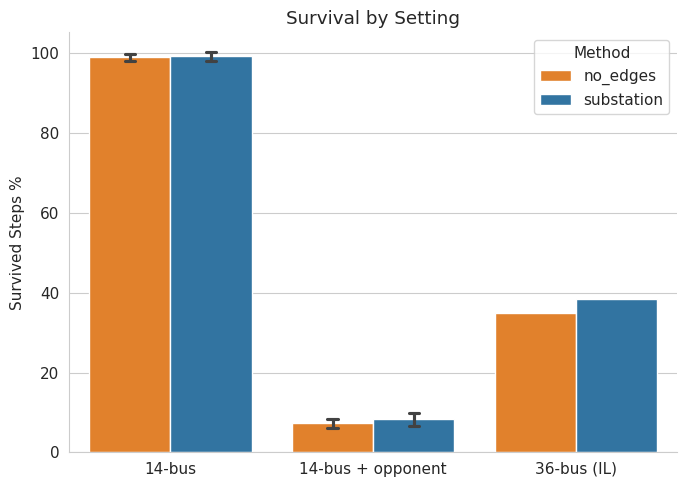

In [8]:
if not df_surv.empty and available_settings:
    sub = df_surv[df_surv["setting"].isin(available_settings)]

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(
        data=sub, x="setting", y="survived_steps_pct", hue="method",
        palette=METHOD_COLORS, errorbar="sd", capsize=0.1, ax=ax,
        order=available_settings,
    )
    ax.set_xlabel("")
    ax.set_ylabel("Survived Steps %")
    ax.set_title("Survival by Setting")
    ax.legend(title="Method")
    sns.despine(ax=ax)
    plt.tight_layout()
    fig.savefig(FIGURES / "survival_by_setting.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No survival data to plot.")

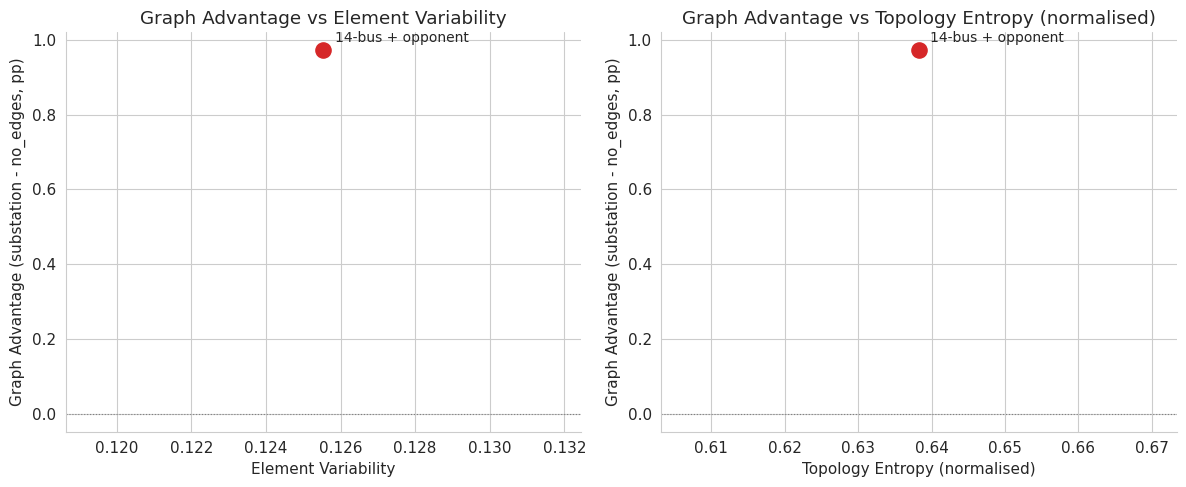


Correlation data:


,element_variability,topology_entropy,graph_advantage_pct
setting,,,
14-bus + opponent,0.125544,0.638326,0.971726


In [9]:
if not df_var.empty and not df_surv.empty and available_settings:
    # Compute per-setting: variability (averaged over both methods) and graph advantage
    corr_records = []
    for setting in available_settings:
        sv = df_var[df_var["setting"] == setting]
        ss = df_surv[df_surv["setting"] == setting]

        if sv.empty or ss.empty:
            continue

        # Variability: average across both methods (environment property)
        elem_var = sv["mean_element_variability"].mean()
        entropy = sv["topology_entropy_normalised"].mean()

        # Advantage: substation survival - no_edges survival (mean over seeds)
        surv_sub = ss.loc[ss["method"] == "substation", "survived_steps_pct"]
        surv_ne = ss.loc[ss["method"] == "no_edges", "survived_steps_pct"]

        if surv_sub.empty or surv_ne.empty:
            continue

        advantage = surv_sub.mean() - surv_ne.mean()
        corr_records.append({
            "setting": setting,
            "element_variability": elem_var,
            "topology_entropy": entropy,
            "graph_advantage_pct": advantage,
        })

    df_corr = pd.DataFrame(corr_records)

    if len(df_corr) >= 1:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        for ax, x_col, x_label in [
            (axes[0], "element_variability", "Element Variability"),
            (axes[1], "topology_entropy", "Topology Entropy (normalised)"),
        ]:
            ax.scatter(
                df_corr[x_col], df_corr["graph_advantage_pct"],
                s=120, zorder=3,
                c=[SETTING_COLORS.get(s, "tab:gray") for s in df_corr["setting"]],
            )
            for _, row in df_corr.iterrows():
                ax.annotate(
                    row["setting"],
                    (row[x_col], row["graph_advantage_pct"]),
                    textcoords="offset points", xytext=(8, 6), fontsize=10,
                )
            # Trend line if >= 2 points
            if len(df_corr) >= 2:
                z = np.polyfit(df_corr[x_col], df_corr["graph_advantage_pct"], 1)
                x_range = np.linspace(df_corr[x_col].min() * 0.9, df_corr[x_col].max() * 1.1, 50)
                ax.plot(x_range, np.polyval(z, x_range), "--", color="gray", alpha=0.5)

            ax.axhline(0, color="gray", lw=0.8, ls=":")
            ax.set_xlabel(x_label)
            ax.set_ylabel("Graph Advantage (substation - no_edges, pp)")
            ax.set_title(f"Graph Advantage vs {x_label}")
            sns.despine(ax=ax)

        plt.tight_layout()
        fig.savefig(FIGURES / "advantage_vs_variability.png", dpi=150, bbox_inches="tight")
        plt.show()

        print("\nCorrelation data:")
        display(df_corr.set_index("setting"))
    else:
        print("Not enough settings with both methods to compute correlation.")
else:
    print("Need both variability and survival data to compute correlation.")

## Per-Element Variability

/tmp/ipykernel_70751/2102895036.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


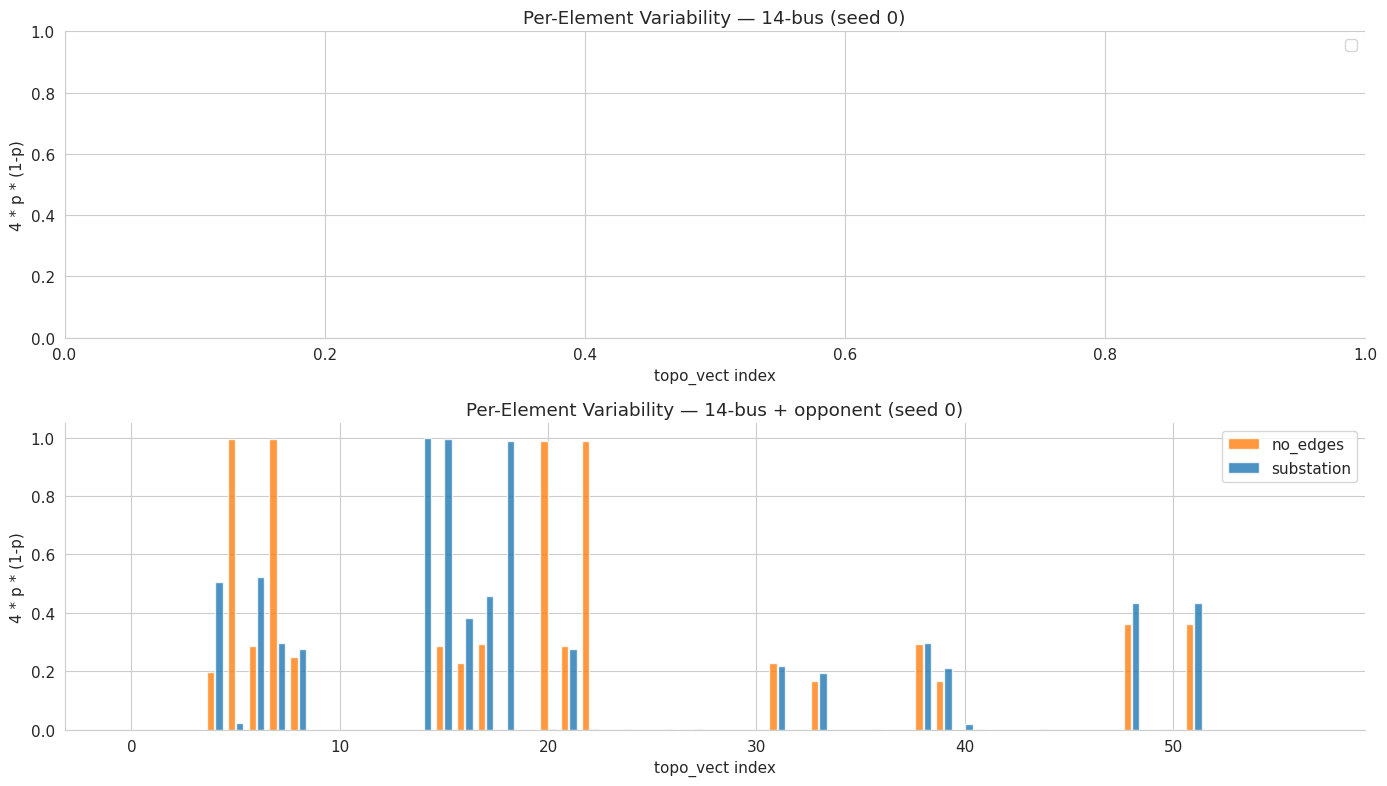

In [10]:
ppo_settings = [s for s in available_settings if s in SETTINGS]

if ppo_settings:
    n_settings = len(ppo_settings)
    fig, axes = plt.subplots(n_settings, 1, figsize=(14, 4 * n_settings), squeeze=False)

    for row, setting in enumerate(ppo_settings):
        ax = axes[row, 0]

        for method, base_dir in SETTINGS[setting].items():
            dirs = sorted(base_dir.glob("CustomPPO*/")) if base_dir.exists() else []
            if not dirs:
                continue
            elem_var = load_element_variability(dirs[0])
            if elem_var is None:
                continue
            x = np.arange(len(elem_var))
            ax.bar(
                x + (0.2 if method == "substation" else -0.2),
                elem_var, width=0.35, alpha=0.8,
                color=METHOD_COLORS[method], label=method,
            )

        ax.set_xlabel("topo_vect index")
        ax.set_ylabel("4 * p * (1-p)")
        ax.set_title(f"Per-Element Variability — {setting} (seed 0)")
        ax.legend()
        sns.despine(ax=ax)

    plt.tight_layout()
    fig.savefig(FIGURES / "element_variability.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No PPO variability data available for per-element plots.")